# Track 00.1 — Foundations and End-to-End RAG Architecture Overview

**Course:** RAG Engineering Academy  
**Track:** 00 — Foundations and Environment  
**Stage:** Stage 1 — Foundations  
**Runtime:** ~45 seconds (100% offline-executable; CPU-friendly)  
**Dependencies:** `requirements/base.txt` (`numpy`, `matplotlib`, `pymupdf`, `chromadb`, `python-dotenv`)  

---

## 1. Orientation & Learning Objectives

Welcome to the **RAG Engineering Academy**. This first notebook establishes the mechanical and theoretical foundations of Retrieval-Augmented Generation (RAG). Before diving into vector stores, document chunking algorithms, or agentic frameworks, we must understand the fundamental physical and computational limits of Large Language Models (LLMs) and why retrieval is the primary architectural solution.

### Learning Objectives
By completing this notebook, you will be able to:
1. **Differentiate Parametric vs. Non-Parametric Memory:** Articulate precisely how static transformer weights differ from dynamic external context.
2. **Quantify the Tokenization & Context Window Barrier:** Understand why context windows are finite and analyze the quadratic computational memory cost ($\mathcal{O}(N^2)$) of self-attention.
3. **Map the 7-Stage RAG Lifecycle:** Trace a document and query through Ingestion, Chunking, Embedding, Indexing, Retrieval, Augmentation, and Generation.
4. **Implement an End-to-End RAG Pipeline from Scratch:** Build a working, deterministic retrieval and prompt synthesis pipeline in pure Python without third-party frameworks.
5. **Verify Local Environment Capabilities:** Confirm that local PDF extraction (`PyMuPDF`) and vector storage (`ChromaDB`) run reliably on your local machine.

---

## 2. The Real-World Problem: The Limits of Parametric Knowledge

Modern Large Language Models (e.g., Llama 3, Gemini, GPT-4) store their world knowledge inside **parametric memory**—billions of floating-point weights adjusted during training. While powerful, relying solely on parametric memory introduces critical enterprise failure modes:

1. **Temporal Cutoffs & Knowledge Decay:** An LLM's parametric memory is frozen at its pre-training cutoff date. Teaching a model new facts via retraining or fine-tuning is computationally prohibitive and risks *catastrophic forgetting* (overwriting previously learned general knowledge).
2. **Hallucination & Fabrication:** When asked about private internal documentation, obscure facts, or rapidly evolving domains, models do not reliably declare ignorance; instead, their next-token prediction objective incentivizes plausible-sounding but completely fictitious outputs.
3. **Absence of Provenance & Verifiable Citations:** A model cannot natively produce verifiable source citations from its weights; it generates citation-like tokens based on statistical co-occurrence, creating "hallucinated bibliography."
4. **Data Privacy & Tenant Isolation:** Training proprietary enterprise knowledge into model weights leaks information across tenant boundaries. You cannot easily "delete" a sensitive document from billions of weights once trained.

**Retrieval-Augmented Generation (RAG)** solves these challenges by separating **reasoning** (the parametric model) from **knowledge** (the non-parametric external index).

---

## 3. Mathematical Intuition: Why Can't We Just Feed "Everything" into Context?

Modern models boast context windows ranging from 32,000 to 1,000,000+ tokens. A naive question often follows: *Why not just dump the entire company documentation into the prompt?*

### 1. The Quadratic Attention Ceiling: $\mathcal{O}(N^2)$
In standard Multi-Head Attention (Vaswani et al., 2017), every token must attend to every other token in the sequence. Given sequence length $N$ and hidden dimension $d_k$, the scaled dot-product attention score matrix is:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

The score matrix $QK^T$ requires computing and storing an $N \times N$ matrix for each attention head across all layers:

$$\text{Memory}_{\text{attention}} = \text{Layers} \times \text{Heads} \times N^2 \times \text{Bytes per Float}$$

As sequence length $N$ scales from 1,000 to 128,000 tokens, memory consumption and compute scale **quadratically**. Even with FlashAttention optimizations, serving massive contexts imposes severe latency, GPU VRAM bottlenecks, and massive dollar costs per request.

### 2. The "Lost in the Middle" Degradation (Liu et al., 2023)
Empirical research demonstrates that LLM retrieval accuracy degrades severely as prompt context balloons. Information located in the middle of long contexts is recalled with significantly lower fidelity than information placed near the absolute beginning or end of the prompt.

**RAG bypasses both bottlenecks** by retrieving only the top-$k$ most relevant, concise information chunks (e.g., $1{,}000$ to $2{,}000$ focused tokens) right when needed.

---

## 4. End-to-End Architecture: The 7-Stage RAG Lifecycle

A production RAG system consists of two distinct operational paths: the **Ingestion Path** (offline or asynchronous) and the **Query Path** (real-time online execution).

```mermaid
flowchart TD
    subgraph INGESTION ["Offline / Asynchronous Ingestion Pipeline"]
        D[Raw Source Documents<br/>PDF, Markdown, HTML] --> P[1. Document Ingestion<br/>PyMuPDF / Parsing]
        P --> C[2. Text Chunking<br/>Recursive / Semantic Splitting]
        C --> E1[3. Embedding Generation<br/>Dense Vector Model]
        E1 --> V[4. Vector Indexing<br/>ChromaDB / HNSW Index]
    end

    subgraph QUERY ["Online Real-Time Query Pipeline"]
        U([User Query]) --> E2[Query Embedding]
        E2 --> R[5. Semantic Retrieval<br/>Cosine Similarity / ANN Search]
        V -.-> R
        R --> A[6. Prompt Augmentation<br/>System Prompt + Cited Context]
        U -.-> A
        A --> G[7. LLM Synthesis<br/>Grounded Output with Citations]
        G --> O([Final Grounded Response])
    end

    style INGESTION fill:#f4f6f8,stroke:#4a5568,stroke-width:2px;
    style QUERY fill:#edf2f7,stroke:#2b6cb0,stroke-width:2px;
```

---


### Step 1: Environment Setup and Root Directory Resolution

- **What we are about to do:** Import Python standard library modules (`pathlib`, `sys`, `typing`) and resolve the project root directory.
- **Why we are doing it:** Ensures that modules from `common/` (such as `Settings` and logging utilities) can be loaded cleanly regardless of the directory from which the Jupyter kernel was started.
- **How it works:** We inspect `Path.cwd()` and traverse upward until finding the repository root containing `pyproject.toml`, prepending it to `sys.path`.
- **What to expect:** A verified project root directory path printed to the console.
- **Caveats:** None; pure standard library.


In [1]:
import os
import sys
from pathlib import Path
from typing import List, Dict, Any, Tuple
import matplotlib.pyplot as plt
import numpy as np

# Resolve project root dynamically
current_dir = Path.cwd().resolve()
if (current_dir / "pyproject.toml").exists():
    project_root = current_dir
elif (current_dir.parent / "pyproject.toml").exists():
    project_root = current_dir.parent
elif (current_dir.parent.parent / "pyproject.toml").exists():
    project_root = current_dir.parent.parent
else:
    project_root = current_dir

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print(f"Project root resolved: {project_root}")


Project root resolved: /Users/bharathm/Documents/Self Learning/RAG_from_scratch


### Step 2: Configuration Loader and Zero-Leakage Environment Check

- **What we are about to do:** Instantiate the shared configuration manager `Settings` from `common.config` and inspect project settings.
- **Why we are doing it:** Validates that environment variables are loaded properly via `python-dotenv` without hardcoding credentials or exposing secret API keys in logs or outputs.
- **How it works:** `Settings` reads `.env` locally. We verify the active LLM provider, vector storage target, and safe masked presence of the Groq API key.
- **What to expect:** A clean configuration diagnostic table showing the local environment status.
- **Caveats:** Does not perform external network calls.


In [2]:
from common.config import Settings

settings = Settings()
groq_status = (
    f"Configured (length: {len(settings.groq_api_key)} chars)"
    if settings.groq_api_key
    else "Not configured (Default offline/mock mode active)"
)

print("-" * 55)
print(f"Project Name        : {settings.project_name}")
print(f"Default Provider    : {settings.llm_provider}")
print(f"Chroma Storage Path : {settings.chroma_persist_directory}")
print(f"Groq API Key Status : {groq_status}")
print("-" * 55)


-------------------------------------------------------
Project Name        : RAG_from_scratch
Default Provider    : groq
Chroma Storage Path : /Users/bharathm/Documents/Self Learning/RAG_from_scratch/storage/chroma
Groq API Key Status : Not configured (Default offline/mock mode active)
-------------------------------------------------------


### Step 3: Minimal End-to-End RAG Pipeline in Pure Python

- **What we are about to do:** Build a complete, functional, first-principles RAG pipeline from scratch using plain Python without external agent frameworks.
- **Why we are doing it:** Frameworks like LangChain or LlamaIndex wrap multiple moving parts. By implementing raw retrieval, prompt augmentation, and grounded synthesis directly, you observe the exact mechanics of RAG before adding abstractions.
- **How it works:**
  1. **Knowledge Base:** Defines a small inline factual fixture (3 documents).
  2. **Retriever:** Implements a lexical Jaccard token-overlap similarity scoring function.
  3. **Augmenter:** Compiles the user query and retrieved passages into an explicit, cited prompt.
  4. **Synthesizer:** A deterministic rule-based generator that strictly limits its answer to retrieved evidence and explicitly abstains if confidence falls below threshold.
- **What to expect:** 
  - Test 1 (Grounded Query) returns an answer with accurate `[DOC-ID]` attribution.
  - Test 2 (Out-of-Domain Query) triggers strict abstention without hallucinations.
- **Caveats:** This demonstrates lexical matching; vector-dense retrieval will be built in Track 02.


In [3]:
# Minimal inline knowledge base fixture (no external files required)
DOCUMENTS = [
    {
        "id": "DOC-1",
        "title": "Retrieval-Augmented Generation Definition",
        "text": "Retrieval-Augmented Generation (RAG) combines an external retrieval mechanism with a generative language model to ground answers in verified non-parametric facts."
    },
    {
        "id": "DOC-2",
        "title": "Vector Databases and Indexing",
        "text": "Vector databases index high-dimensional embeddings and utilize approximate nearest neighbor (ANN) search such as HNSW graphs to retrieve semantically similar chunks."
    },
    {
        "id": "DOC-3",
        "title": "Context Window Scaling and Attention",
        "text": "Transformer self-attention scales quadratically O(N^2) with sequence length, making selective context retrieval significantly more computationally efficient than whole-corpus prompt stuffing."
    }
]

def tokenize(text: str) -> set:
    """Extract lowercase alphanumeric tokens for word-level overlap."""
    import re
    return set(re.findall(r"\b[a-z0-9]+\b", text.lower()))

def retrieve_top_k(query: str, corpus: list, k: int = 2, threshold: float = 0.05) -> list:
    """Score and retrieve documents based on Jaccard token similarity."""
    q_tokens = tokenize(query)
    if not q_tokens:
        return []
    
    scored = []
    for doc in corpus:
        d_tokens = tokenize(doc["title"] + " " + doc["text"])
        intersection = q_tokens.intersection(d_tokens)
        union = q_tokens.union(d_tokens)
        score = len(intersection) / len(union) if union else 0.0
        if score >= threshold:
            scored.append((doc, score))
            
    scored.sort(key=lambda item: item[1], reverse=True)
    return scored[:k]

def build_augmented_prompt(query: str, retrieved: list) -> str:
    """Assemble prompt with system guardrails and cited context blocks."""
    context_lines = []
    for doc, score in retrieved:
        context_lines.append(f"[{doc['id']}] {doc['title']}: {doc['text']}")
    context_str = "\n".join(context_lines) if context_lines else "(No relevant documents retrieved)"
    
    prompt = (
        "SYSTEM: You are a grounded AI assistant. Answer using ONLY the provided context blocks.\n"
        "Cite your sources with [Doc-ID]. If the context lacks sufficient evidence, state 'I do not have sufficient information.'\n\n"
        f"CONTEXT:\n{context_str}\n\n"
        f"USER QUERY: {query}\n"
        "GROUNDED ANSWER:"
    )
    return prompt

def deterministic_synthesizer(query: str, retrieved: list) -> str:
    """Rule-based grounded synthesizer demonstrating strict attribution and abstention."""
    if not retrieved:
        return "I do not have sufficient information to answer this query based on the retrieved documents."
    
    top_doc, score = retrieved[0]
    return f"Based on [{top_doc['id']}], {top_doc['text']} [Retrieval Confidence: {score:.2f}]"

# --- Experiment Execution ---
print("=== EXPERIMENT 1: In-Domain Grounded Query ===")
q1 = "What is Retrieval-Augmented Generation and how does it ground answers?"
matches_1 = retrieve_top_k(q1, DOCUMENTS, k=1)
prompt_1 = build_augmented_prompt(q1, matches_1)
answer_1 = deterministic_synthesizer(q1, matches_1)

print(f"Query: '{q1}'")
print(f"Retrieved Document: {matches_1[0][0]['id']} (Score: {matches_1[0][1]:.3f})")
print(f"Generated Output:\n{answer_1}\n")

print("=== EXPERIMENT 2: Out-of-Domain Query (Abstention Test) ===")
q2 = "What is the orbital velocity of the International Space Station?"
matches_2 = retrieve_top_k(q2, DOCUMENTS, k=1)
answer_2 = deterministic_synthesizer(q2, matches_2)

print(f"Query: '{q2}'")
print(f"Retrieved: {matches_2}")
print(f"Generated Output:\n{answer_2}")


=== EXPERIMENT 1: In-Domain Grounded Query ===
Query: 'What is Retrieval-Augmented Generation and how does it ground answers?'
Retrieved Document: DOC-1 (Score: 0.179)
Generated Output:
Based on [DOC-1], Retrieval-Augmented Generation (RAG) combines an external retrieval mechanism with a generative language model to ground answers in verified non-parametric facts. [Retrieval Confidence: 0.18]

=== EXPERIMENT 2: Out-of-Domain Query (Abstention Test) ===
Query: 'What is the orbital velocity of the International Space Station?'
Retrieved: []
Generated Output:
I do not have sufficient information to answer this query based on the retrieved documents.


### Step 4: Mathematical Simulation & Visualization: Attention Growth vs. RAG

- **What we are about to do:** Simulate and visualize the quadratic memory growth of transformer self-attention ($\mathcal{O}(N^2)$) compared to a RAG pipeline's bounded context retrieval footprint.
- **Why we are doing it:** Gives learners an immediate visual and computational understanding of why retrieval is a fundamental scaling necessity, rather than just an engineering convenience.
- **How it works:**
  - Evaluates standard 7B/8B parameter transformer specs ($32$ layers, $32$ attention heads, FP16 precision).
  - Calculates attention matrix memory overhead in Megabytes for context sizes $N \in [512, 128{,}000]$ tokens.
  - Plots a dual-panel chart:
    1. Attention score matrix memory vs. Sequence length (quadratic curve).
    2. Tokens delivered to the LLM: Full Ingestion vs. RAG fixed-$k$ context ($3 	imes 512 = 1{,}536$ tokens).
- **What to expect:** A dual-panel Matplotlib figure illustrating quadratic vs. constant complexity.
- **Caveats:** CPU-bound simulation; renders in < 1 second.


Memory at 8k tokens   : 131072.0 MB
Memory at 128k tokens : 33554432.0 MB (x256 increase!)


<ipython-input-1-f3947653697a>:34: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


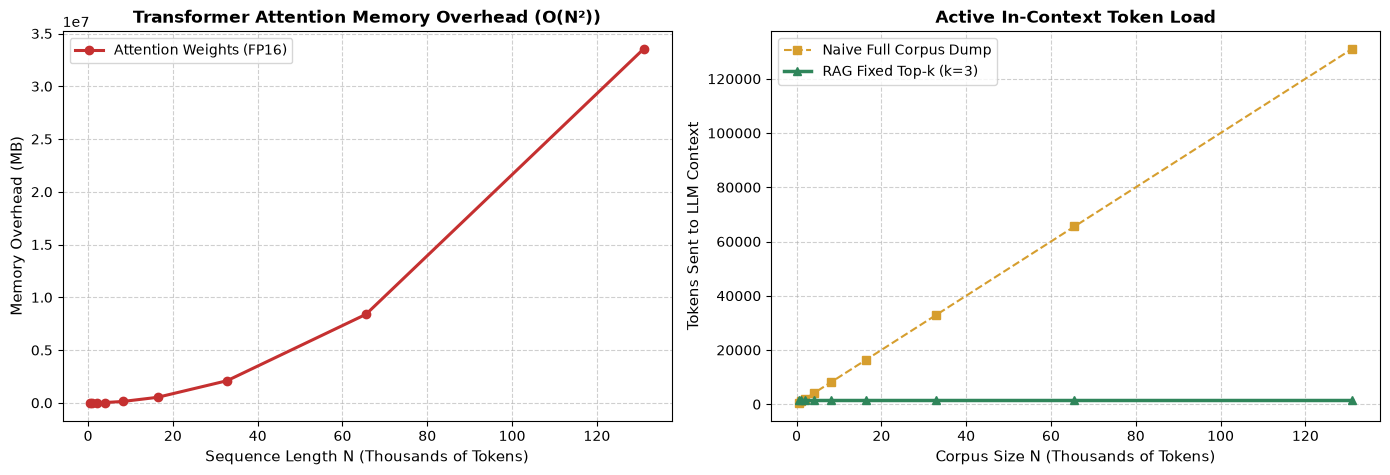

In [4]:
# Model architecture parameters (representative 7B model: 32 layers, 32 heads, 2 bytes/float16)
layers = 32
heads = 32
bytes_per_elem = 2

seq_lengths = np.array([512, 1024, 2048, 4096, 8192, 16384, 32768, 65536, 131072])

# Memory per head is N x N elements; total memory across all heads and layers (in MB)
attn_matrix_mb = (layers * heads * (seq_lengths ** 2) * bytes_per_elem) / (1024 ** 2)

# RAG fixed context size (e.g. k=3 retrieved chunks of 512 tokens = 1536 tokens fixed)
rag_tokens = np.full_like(seq_lengths, 1536)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Attention Matrix Memory Curve
ax1.plot(seq_lengths / 1000, attn_matrix_mb, marker='o', color='#c53030', linewidth=2.2, label="Attention Weights (FP16)")
ax1.set_title("Transformer Attention Memory Overhead (O(N²))", fontsize=12, fontweight="bold")
ax1.set_xlabel("Sequence Length N (Thousands of Tokens)", fontsize=11)
ax1.set_ylabel("Memory Overhead (MB)", fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="upper left")

# Subplot 2: Prompt Size: Full Corpus Dump vs RAG Top-k
ax2.plot(seq_lengths / 1000, seq_lengths, marker='s', color='#d69e2e', linestyle='--', label="Naive Full Corpus Dump")
ax2.plot(seq_lengths / 1000, rag_tokens, marker='^', color='#2f855a', linewidth=2.5, label="RAG Fixed Top-k (k=3)")
ax2.set_title("Active In-Context Token Load", fontsize=12, fontweight="bold")
ax2.set_xlabel("Corpus Size N (Thousands of Tokens)", fontsize=11)
ax2.set_ylabel("Tokens Sent to LLM Context", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()

print(f"Memory at 8k tokens   : {attn_matrix_mb[4]:.1f} MB")
print(f"Memory at 128k tokens : {attn_matrix_mb[-1]:.1f} MB (x{attn_matrix_mb[-1]/attn_matrix_mb[4]:.0f} increase!)")


### Step 5: Local Component Smoke Test (PyMuPDF & ChromaDB)

- **What we are about to do:** Perform quick, in-memory smoke checks on `PyMuPDF` (`fitz`) and `ChromaDB`.
- **Why we are doing it:** Validates that the core tools powering Track 01 (Document Ingestion) and Track 02 (Vector Indexing) are correctly installed and functional in our `.venv312` environment.
- **How it works:**
  1. Uses PyMuPDF to create a synthetic in-memory PDF page and extracts text.
  2. Uses ChromaDB's in-memory `EphemeralClient` to build a temporary collection, index two documents, and query them.
- **What to expect:** Confirmation printouts displaying installed versions and successful query execution.
- **Caveats:** Operates strictly in memory; leaves no persistent artifacts on disk.


In [5]:
import pymupdf as fitz
import chromadb

# 1. PyMuPDF In-Memory Text Extraction Test
doc = fitz.open()  # new blank PDF in memory
page = doc.new_page()
test_phrase = "RAG Engineering Academy: PyMuPDF verification test."
page.insert_text((50, 72), test_phrase)
extracted = doc[0].get_text().strip()
doc.close()

print(f"[OK] PyMuPDF v{fitz.__version__}: In-memory test passed -> '{extracted}'")

# 2. ChromaDB Ephemeral Client Test
chroma = chromadb.EphemeralClient()
test_collection = chroma.create_collection(name="academy_smoke_test")
test_collection.add(
    ids=["chunk_1", "chunk_2"],
    documents=["RAG Architecture Foundations", "Dense Embedding Spaces"]
)
query_res = test_collection.query(query_texts=["Foundations of RAG"], n_results=1)
matched_id = query_res["ids"][0][0]
matched_dist = query_res["distances"][0][0]

print(f"[OK] ChromaDB v{chromadb.__version__}: Ephemeral search matched ID '{matched_id}' (Distance: {matched_dist:.4f})")


[OK] PyMuPDF v2.1: In-memory test passed -> 'RAG Engineering Academy: PyMuPDF verification test.'
[OK] ChromaDB v1.5.9: Ephemeral search matched ID 'chunk_1' (Distance: 0.3701)


### Step 6: Optional Live Model Synthesis (Groq API)

- **What we are about to do:** Provide an optional execution cell to invoke live LLM generation using the official Groq SDK (`groq.Groq`).
- **Why we are doing it:** Connects our scratch prompt builder to a live production model (`llama-3.3-70b-versatile`) so learners can observe real-world instruction adherence on cited prompts.
- **How it works:** Checks if `settings.groq_api_key` is present and whether the user explicitly toggled `ENABLE_LIVE_API = True`. If enabled, sends the augmented prompt from Step 3 to Groq.
- **What to expect:** When disabled (`ENABLE_LIVE_API = False`), prints a polite skip notification. When enabled with a valid key, prints the live streaming completion and exact token usage.
- **Caveats:** **API QUOTA NOTICE:** This cell consumes live Groq tokens if enabled. It is disabled by default to maintain zero cost.


In [6]:
# Set to True only when you explicitly wish to consume Groq API tokens
ENABLE_LIVE_API = False

if not ENABLE_LIVE_API:
    print("[INFO] Live Groq API cell is disabled (ENABLE_LIVE_API = False).")
    print("Set ENABLE_LIVE_API = True and verify GROQ_API_KEY in .env to run live model synthesis.")
elif not settings.groq_api_key:
    print("[WARNING] ENABLE_LIVE_API is True, but no GROQ_API_KEY was found in .env.")
    print("Add GROQ_API_KEY to your root .env file to enable live inference.")
else:
    try:
        from groq import Groq
        client = Groq(api_key=settings.groq_api_key)
        
        response = client.chat.completions.create(
            model="llama-3.3-70b-versatile",
            messages=[{"role": "user", "content": prompt_1}],
            temperature=0.0,
            max_tokens=150
        )
        print("=== LIVE GROQ COMPLETION ===")
        print(response.choices[0].message.content)
        print("-" * 40)
        print(f"Token Consumption: Prompt={response.usage.prompt_tokens}, Completion={response.usage.completion_tokens}")
    except Exception as err:
        print(f"[ERROR] Groq API call failed: {err}")


[INFO] Live Groq API cell is disabled (ENABLE_LIVE_API = False).
Set ENABLE_LIVE_API = True and verify GROQ_API_KEY in .env to run live model synthesis.


### Step 7: Automated Self-Verification Assertions

- **What we are about to do:** Execute automated unit assertions validating the correctness of our scratch RAG pipeline.
- **Why we are doing it:** In accordance with the academy's test-driven learning standard (AGENTS.md §E.5), each notebook must programmatically verify its core logic before completion.
- **How it works:** Runs four assertions:
  1. Relevant query returns the correct top chunk `DOC-1`.
  2. Out-of-domain query produces an empty retrieval set.
  3. Augmented prompt contains required formatting and citation markers.
  4. Synthesizer reliably executes abstention logic when given empty context.
- **What to expect:** Confirmation message: `[PASS] All 4 notebook assertions verified successfully.`
- **Caveats:** Fast, deterministic, runs in memory.


In [7]:
# Assertion 1: Grounded query retrieves DOC-1 with positive score
r1 = retrieve_top_k("Retrieval-Augmented Generation", DOCUMENTS, k=1)
assert len(r1) == 1, "Expected exactly 1 document retrieved"
assert r1[0][0]["id"] == "DOC-1", f"Expected DOC-1, got {r1[0][0]['id']}"
assert r1[0][1] > 0.0, "Expected positive similarity score"

# Assertion 2: Nonsense query returns 0 documents above threshold
r2 = retrieve_top_k("Quantum tachyon warp mechanics", DOCUMENTS, k=1)
assert len(r2) == 0, f"Expected 0 documents for OOD query, got {len(r2)}"

# Assertion 3: Prompt assembler correctly embeds document ID citation brackets
test_prompt = build_augmented_prompt("Sample Query", r1)
assert "[DOC-1]" in test_prompt, "Prompt must include document ID citation"
assert "SYSTEM:" in test_prompt, "Prompt must contain system directives"

# Assertion 4: Synthesizer correctly abstains on empty context
empty_ans = deterministic_synthesizer("Sample Query", [])
assert "I do not have sufficient information" in empty_ans, "Synthesizer must abstain on empty context"

print("[PASS] All 4 notebook assertions verified successfully.")


[PASS] All 4 notebook assertions verified successfully.


---

## 5. Failure Modes & Limitations in First-Principles RAG

Even in a minimal RAG pipeline, critical failure modes emerge:

| Failure Mode | Mechanism | Production Impact | Mitigation Strategy |
|---|---|---|---|
| **Lexical Mismatch** | Jaccard/keyword search fails when user query uses synonyms not present in doc text (e.g. "LLM grounding" vs "RAG definition"). | High false negatives; retrieval returns empty. | Dense vector embeddings and semantic search (covered in Track 02 & Track 03). |
| **Distractor Interference** | Irrelevant chunks that share common words get retrieved alongside relevant chunks. | The LLM may hallucinate based on irrelevant or contradictory context. | Cross-encoder reranking and contextual filtering (Track 03). |
| **Lost in the Middle** | Crucial factual details placed in the middle of long contexts are ignored by the model. | Incorrect answers despite having the right document retrieved. | Chunk size optimization and re-ordering retrieved chunks by relevance (Track 01 & 03). |
| **Stale / Duplicate Chunks** | Outdated document versions indexed into the vector store. | Answering with obsolete facts. | Document versioning, metadata filtering, and TTL policies (Track 14). |

---

## 6. Hands-On Exercise: Implementing Length-Normalized Scoring

**Objective:** The Jaccard similarity implementation in Step 3 is sensitive to document length—very long documents have larger union denominators, penalizing their scores even if they contain the exact answer.

**Your Challenge:**
1. Copy the `retrieve_top_k` function into a new scratch cell below.
2. Modify the scoring formula to implement **BM25 length normalization intuition**:
   $$\text{Score}_{\text{norm}} = \frac{\text{Intersection}}{\text{Intersection} + (1 - b) + b \cdot \left(\frac{\text{Doc Length}}{\text{Avg Doc Length}}\right)}$$
   where $b = 0.75$.
3. Test your implementation with documents of varying lengths and verify if short and long documents compete fairly.

---

## 7. Concept Check: Interview Questions

Try answering these questions before checking the explanations:

1. **Why is RAG generally preferred over fine-tuning for proprietary organizational knowledge?**
   > *Explanation:* Fine-tuning adjusts model parameters to adopt a style, tone, or specific syntax, but is inefficient and unreliable for factual knowledge storage. Fine-tuning causes catastrophic forgetting, cannot provide verified source citations, and requires expensive retraining whenever internal documents are updated. RAG separates reasoning (the model) from knowledge (the external database), enabling instant updates, granular access control (ACLs), and exact citations.

2. **What computational factor causes the quadratic memory scaling in standard self-attention?**
   > *Explanation:* Multi-Head Attention computes scaled dot products between every Query token and every Key token across all $N$ tokens in the sequence ($QK^T$). This produces an $N \times N$ attention weight matrix per head per layer. As sequence length $N$ grows, the size of this matrix grows with $N^2$.

3. **How does context augmentation change the risk profile of prompt injection?**
   > *Explanation:* In a basic LLM, prompt injection comes directly from the user query. In RAG, untrusted content retrieved from external sources (e.g., public web pages, customer emails, uploaded PDFs) is placed directly into the model's system context. An attacker can place hidden adversarial instructions inside an indexed document (*indirect prompt injection*), which triggers when retrieved.

---

## 8. Authoritative References & Further Reading

- **Lewis et al. (2020):** *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks* (The foundational RAG paper) — [arXiv:2005.11401](https://arxiv.org/abs/2005.11401)
- **Vaswani et al. (2017):** *Attention Is All You Need* (Transformer mechanics and attention complexity) — [arXiv:1706.03762](https://arxiv.org/abs/1706.03762)
- **Liu et al. (2023):** *Lost in the Middle: How Language Models Use Long Contexts* — [arXiv:2307.03172](https://arxiv.org/abs/2307.03172)
- **PyMuPDF Documentation:** [pymupdf.readthedocs.io](https://pymupdf.readthedocs.io/)
- **ChromaDB Documentation:** [docs.trychroma.com](https://docs.trychroma.com/)

---

## 9. Summary & Next Notebook Preview

In this notebook, we established:
- Why parametric memory alone cannot support enterprise knowledge applications.
- How the 7-stage RAG lifecycle decouples reasoning from external knowledge retrieval.
- How to implement a grounded RAG pipeline from first principles in pure Python.
- Why context window growth does not eliminate the need for intelligent retrieval.

**Next Up in Stage 1:**  
👉 **Track 01 — Ingestion and Chunking:** We move to the document ingestion boundary, mastering high-fidelity PDF extraction with `PyMuPDF` and implementing recursive, semantic, and structural chunking strategies.
